# Qiskit Fall Fest 2026 - Challenge 1: Predict the Output

In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

sim = AerSimulator()
SHOTS = 100

## Circuit A: X gate + measure


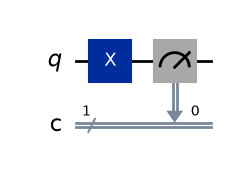

In [2]:
qc_a = QuantumCircuit(1, 1, name="Circuit A")
qc_a.x(0)
qc_a.measure(0, 0)

display(qc_a.draw("mpl"))

### Prediction for Circuit A
X gate flips |0> to |1>, so I expect 100% '1' (all 100 shots).

Circuit A results: {'1': 100}


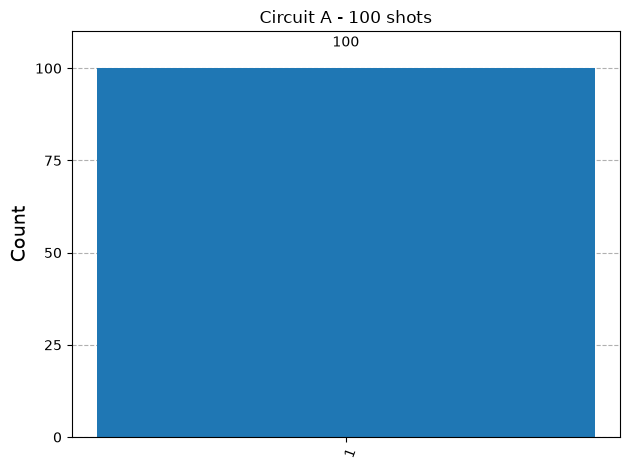

In [3]:
job_a = sim.run(qc_a, shots=SHOTS)
counts_a = job_a.result().get_counts()
print("Circuit A results:", counts_a)
display(plot_histogram(counts_a, title="Circuit A - 100 shots"))

## Circuit B: Two X gates + measure

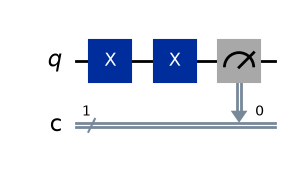

In [4]:
qc_b = QuantumCircuit(1, 1, name="Circuit B")
qc_b.x(0)
qc_b.x(0)
qc_b.measure(0, 0)

display(qc_b.draw("mpl"))

### Prediction for Circuit B
The second X flips the qubit back to |0>, so I expect 100% '0' (all 100 shots).

Circuit B results: {'0': 100}


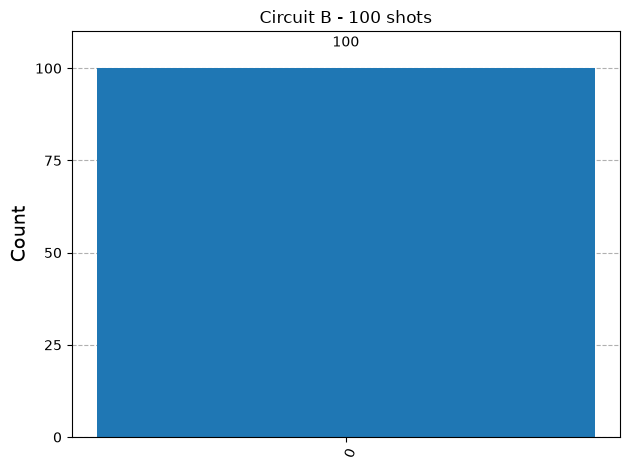

In [5]:
job_b = sim.run(qc_b, shots=SHOTS)
counts_b = job_b.result().get_counts()
print("Circuit B results:", counts_b)
display(plot_histogram(counts_b, title="Circuit B - 100 shots"))

## Circuit C: H gate + measure

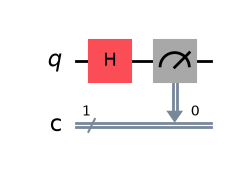

In [6]:
qc_c = QuantumCircuit(1, 1, name="Circuit C")
qc_c.h(0)
qc_c.measure(0, 0)

display(qc_c.draw("mpl"))

### Prediction for Circuit C
H creates an equal superposition, so I expect roughly 50% '0' and 50% '1'. It will not always give the same result; each shot is random.

Circuit C results: {'0': 48, '1': 52}


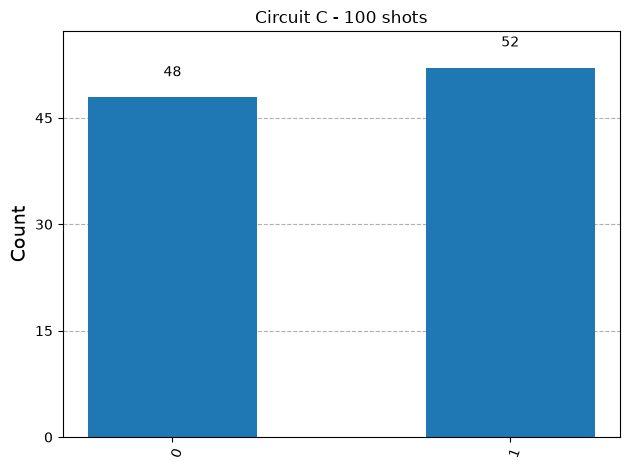

In [7]:
job_c = sim.run(qc_c, shots=SHOTS)
counts_c = job_c.result().get_counts()
print("Circuit C results:", counts_c)
display(plot_histogram(counts_c, title="Circuit C - 100 shots"))

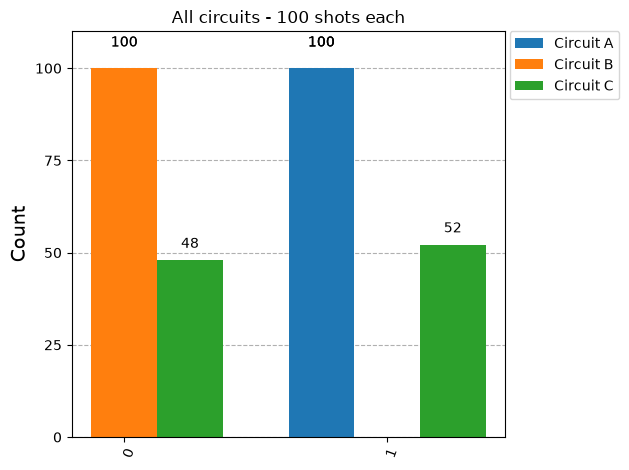

In [8]:
plot_histogram([counts_a, counts_b, counts_c],
               legend=["Circuit A", "Circuit B", "Circuit C"],
               title="All circuits - 100 shots each")

## Comparison: Prediction vs Actual
- **Circuit A:** Predicted all '1'. Actual: {'1': 100}. Matched.
- **Circuit B:** Predicted all '0'. Actual: {'0': 100}. Matched, because X followed by X returns the qubit to |0>.
- **Circuit C:** Predicted about 50/50. Actual: {'0': __, '1': __} (write your numbers). Close to 50/50 but not exact, because measurement is probabilistic.

**Conclusion:** X gates give a fixed (deterministic) result. The H gate gives a random result on each shot, so Circuit C does not always give the same result and the counts change slightly every run.